In [30]:
import matplotlib.pyplot as plt
import pandas as pd
from scipy.ndimage.filters import gaussian_filter1d
import seaborn as sns

# Function to apply Gaussian smoothing
def smooth_gaussian(x, y):
    y_smoothed = gaussian_filter1d(y, sigma=1)
    return x, y_smoothed

/tmp/ipykernel_695527/3797897512.py:3: DeprecationWarning: Please import `gaussian_filter1d` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  from scipy.ndimage.filters import gaussian_filter1d


In [7]:
# import matplotlib.pyplot as plt
# import numpy as np
# import pandas as pd


# def plot_for_model(model, rho_name):
#     cmap = plt.get_cmap("coolwarm")

#     # Adjust font size for a two-column LaTeX document
#     font_size = 22*1.5
#     plt.rcParams.update(
#         {
#             "font.size": font_size,
#             "axes.titlesize": font_size,
#             "axes.labelsize": font_size,
#             "xtick.labelsize": font_size,
#             "ytick.labelsize": font_size,
#             "legend.fontsize": font_size,
#             "figure.titlesize": font_size,
#         }
#     )

#     # Create the plot
#     fig, ax = plt.subplots(figsize=(10, 6))  # Adjust figure size to fit a two-column layout

#     # Load and preprocess the data
#     df = pd.read_csv("project.csv")
#     df = df.dropna()
#     df = df[df["model"] == model]
#     df = df[df["data.rho_name"] == rho_name]
#     df["data.rho_param"] = df["data.rho_param"].apply(lambda x: eval(x)["alpha"])

#     # Scatter plot
#     ax.scatter(
#         df["data.rho_param"],
#         df["train/rLoss1_epoch.min"],
#         label="Train Loss",
#         s=30,
#         color=cmap(0.4),
#     )

#     # Group by `data.rho_param` and find minimum loss
#     grouped_min = df.groupby("data.rho_param")["train/rLoss1_epoch.min"].min().reset_index()

#     grouped_max = df.groupby("data.rho_param")["train/rLoss1_epoch.min"].max().reset_index()

#     # Connect the minimum loss values for each alpha
#     ax.plot(
#         grouped_min["data.rho_param"],
#         grouped_min["train/rLoss1_epoch.min"],
#         color=cmap(0),
#         linestyle="-",
#         linewidth=2,
#         label="Min Loss per Alpha",
#     )
#     ax.plot(
#         grouped_max["data.rho_param"],
#         grouped_max["train/rLoss1_epoch.min"],
#         color=cmap(0),
#         linestyle="-",
#         linewidth=2,
#         label="Min Loss per Alpha",
#     )
#     print(grouped_min)
#     ax.fill_between(
#         grouped_max["data.rho_param"],
#         grouped_min["train/rLoss1_epoch.min"],
#         grouped_max["train/rLoss1_epoch.min"],
#         color=cmap(0.5),  # A mix between the min and max color
#         alpha=0.3,
#         label="Loss Range",
#     )

#     # Set logarithmic scale for the y-axis
#     ax.set_yscale("log")

#     # Labels and legend
#     # ax.set_xlabel("Alpha (data.rho_param)")
#     # ax.set_ylabel("Train Loss (train/rLoss1_epoch.min)")
#     # ax.legend()

#     # Display the plot
#     plt.show()

In [20]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


def plot_for_model(model, rho_name):
    cmap = plt.get_cmap("coolwarm")

    # Adjust font size for a two-column LaTeX document
    font_size = 22 * 1.5
    plt.rcParams.update(
        {
            "font.size": font_size,
            "axes.titlesize": font_size,
            "axes.labelsize": font_size,
            "xtick.labelsize": font_size,
            "ytick.labelsize": font_size,
            "legend.fontsize": font_size,
            "figure.titlesize": font_size,
        }
    )

    # Create the plot
    fig, ax = plt.subplots(figsize=(10, 6))  # Adjust figure size to fit a two-column layout

    # Load and preprocess the data
    df = pd.read_csv("project.csv")
    df = df.dropna()
    df = df[df["model"] == model]
    df = df[df["data.rho_name"] == rho_name]
    df["data.rho_param"] = df["data.rho_param"].apply(lambda x: eval(x)["alpha"])

    # Using seaborn's lineplot to plot the min and max values of 'train/rLoss1_epoch.min'
    # Group by `data.rho_param` and find minimum and maximum loss
    # grouped_min = df.groupby("data.rho_param")["train/rLoss1_epoch.min"].min().reset_index()
    # grouped_max = df.groupby("data.rho_param")["train/rLoss1_epoch.min"].max().reset_index()

    # Plot using seaborn lineplot
    sns.lineplot(
        data=df,
        x="data.rho_param",
        y="train/rLoss1_epoch.min",
        # label="Min Loss per Alpha",
        ax=ax,
        color=cmap(0.8),
        linewidth=2,
    )
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.set_yscale("log")
    
    ax.tick_params(axis='both', width=2)  # Adjust width of both x and y ticks
    for spine in ax.spines.values():
        spine.set_linewidth(2)  # Set the border thickness (box)
    
    plt.show()
    

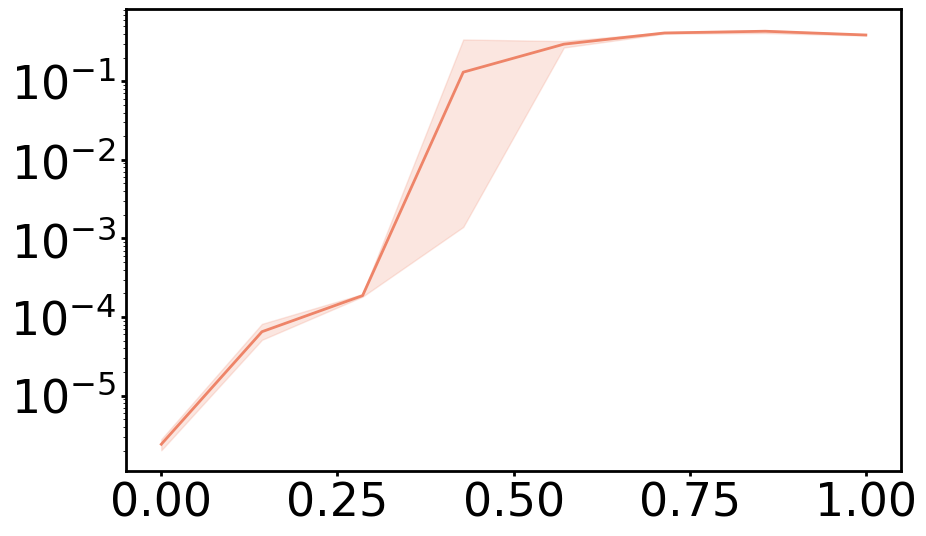

In [21]:
plot_for_model(model="gru", rho_name="airy")